                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1

Class Distribution:
spam
0    4360
1    1368
Name: count, dtype: int64

Precision: 0.9715302491103203
Recall: 0.9963503649635036
F1 Score: 0.9837837837837838

Confusion Matrix:
[[864   8]
 [  1 273]]


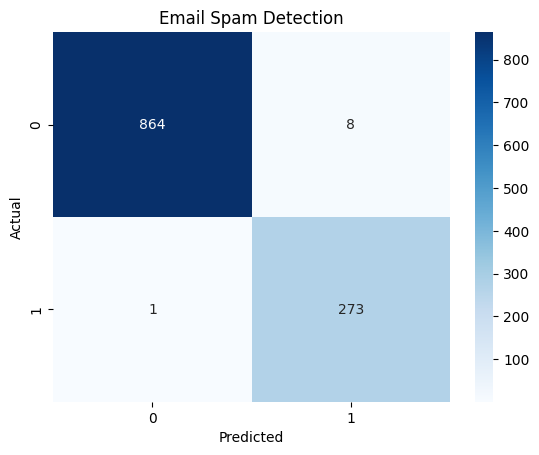

New Email: Spam


In [4]:

import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    precision_score, recall_score,
    f1_score, confusion_matrix
)

# 1. Load dataset
df = pd.read_csv("emails.csv")

print(df.head())
print("\nClass Distribution:")
print(df["spam"].value_counts())

# 2. Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text"] = df["text"].apply(clean_text)

# Separate messages and labels
X = df["text"]
y = df["spam"]

# 3 and 4. Split data and convert text into numbers
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = CountVectorizer()

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

# 5. Train Multinomial Naive Bayes
model = MultinomialNB()
model.fit(X_train, y_train)

# 6. Predict test messages
y_pred = model.predict(X_test)

# 7. Evaluate model
print("\nPrecision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Email Spam Detection")
plt.show()

# Predict a new email
new_email = ["Congratulations! You have won a free prize. Click here now!"]

new_email = vectorizer.transform(new_email)

prediction = model.predict(new_email)

if prediction[0] == 1:
    print("New Email: Spam")
else:
    print("New Email: Not Spam")
